# Random Forest — Sakura

## 1. Model Overview

Random Forest is an ensemble of decision trees trained **in parallel**. Each tree is grown on a
bootstrap sample of the training data, and at every split it only considers a random subset of
the features (`max_features`). The forest prediction is the average of all trees:

$$\hat{f}_{RF}(x) = \frac{1}{B}\sum_{b=1}^{B} T_b(x)$$

A single deep tree has low bias but very high variance: small changes in the data produce a very
different tree. Averaging $B$ trees whose errors are only partly correlated reduces that variance.
If each tree has variance $\sigma^2$ and pairwise correlation $\rho$, the variance of the average is

$$\rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2 .$$

Adding trees shrinks the second term, and subsampling features (smaller `max_features`) lowers
$\rho$, which shrinks the first term. Section 5 checks this on our data.

We use the shared eligible records, the 81 shared input features and the chronological split from
`02_Preprocessing.ipynb`. Tree models do not need scaling, so we use `make_tree_encoder()`
(unscaled numerical inputs, ordinal category codes). Hyperparameters are selected on the 2024
validation set using **validation RMSE**, as for Ridge. The 2025 test set is used once, at the end.

## 2. Load the Shared Data

In [1]:
import sys
sys.path.append("..")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from shared_preprocessing import (
    load_splits, make_tree_encoder, NUMERIC_FEATURES, CATEGORICAL_FEATURES
)

X_train, y_train, X_val, y_val, X_test, y_test = load_splits("../data/stage2_outputs")

print("Training:  ", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:      ", X_test.shape, y_test.shape)

Training:   (276685, 81) (276685,)
Validation: (30545, 81) (30545,)
Test:       (31535, 81) (31535,)


We use the same metric definitions as the other model notebooks. The encoder is fitted **once on
the 2017–2023 training data** and reused for every experiment, which avoids re-encoding for each
configuration. Validation and test data are only transformed.

In [2]:
def evaluate_predictions(name, y_true, y_pred):
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

# Encoder fitted on training data only
tree_encoder = make_tree_encoder().fit(X_train)
feature_names = NUMERIC_FEATURES + CATEGORICAL_FEATURES

Xtr = tree_encoder.transform(X_train).astype(np.float32)
Xva = tree_encoder.transform(X_val).astype(np.float32)
Xte = tree_encoder.transform(X_test).astype(np.float32)
print("Encoded shapes:", Xtr.shape, Xva.shape, Xte.shape)

# Training-mean baseline (same as Ridge / Gradient Boosting)
train_mean = float(y_train.mean())
baseline_val = evaluate_predictions("Mean baseline", y_val, np.full(len(y_val), train_mean))
pd.DataFrame([baseline_val]).round(4)

Encoded shapes: (276685, 81) (30545, 81) (31535, 81)


,model,MAE,RMSE,R2
0,Mean baseline,227823.9716,444016.5549,-0.0463


## 3. Reference: a Single Decision Tree

Before building a forest, we fit one fully grown regression tree. It shows the problem Random Forest
is designed to solve: an unpruned tree almost memorises the training data but generalises much worse.

In [3]:
start = time.time()
single_tree = DecisionTreeRegressor(random_state=42).fit(Xtr, y_train)

# Training fit is measured on a fixed 30,000-row sample to keep this quick
rng = np.random.default_rng(42)
train_sample = rng.choice(len(Xtr), size=30_000, replace=False)

tree_results = pd.DataFrame([
    {**evaluate_predictions("Single tree", y_train.iloc[train_sample],
                            single_tree.predict(Xtr[train_sample])), "split": "Training (sample)"},
    {**evaluate_predictions("Single tree", y_val, single_tree.predict(Xva)), "split": "Validation 2024"},
])[["split", "model", "MAE", "RMSE", "R2"]]

print(f"Depth: {single_tree.get_depth()} | leaves: {single_tree.get_n_leaves():,} | "
      f"fit time: {time.time() - start:.1f}s")
tree_results.round(4)

Depth: 66 | leaves: 257,079 | fit time: 32.3s


,split,model,MAE,RMSE,R2
0,Training (sample),Single tree,3338.8284,17867.5955,0.9975
1,Validation 2024,Single tree,125782.0201,233691.5481,0.7102


## 4. Hyperparameter Tuning on the 2024 Validation Set

We tune the three parameters in the project plan in three stages. Other settings stay fixed:
bootstrap sampling, `min_samples_leaf=1`, `random_state=42`.

1. **`max_features`**: the share of features considered at each split. Smaller values make trees
   more different from each other (lower correlation) but each tree slightly weaker.
   Candidates: √p (≈ 0.11), 0.2, 0.33, 0.5 and 1.0 (all features, i.e. plain bagging), with
   `max_depth=20` and 50 trees.
2. **`max_depth`**: candidates 10, 15, 20, 25 and unlimited, using the best `max_features` and 50 trees.
3. **`n_estimators`**: with the two settings fixed, we grow the forest from 10 to 200 trees
   (`warm_start`) and record validation error at each size.

Fifty trees are enough to rank configurations reliably; the number of trees is tuned separately in
stage 3. The selection metric throughout is validation RMSE.

In [4]:
def fit_forest(n_estimators, max_features, max_depth, **kwargs):
    model = RandomForestRegressor(
        n_estimators=n_estimators,
        max_features=max_features,
        max_depth=max_depth,
        min_samples_leaf=1,
        n_jobs=-1,
        random_state=42,
        **kwargs,
    )
    return model.fit(Xtr, y_train)

tuning_rows = []

# Stage 1: max_features
for max_features in ["sqrt", 0.2, 0.33, 0.5, 1.0]:
    start = time.time()
    model = fit_forest(50, max_features, 20)
    result = evaluate_predictions(f"RF max_features={max_features}", y_val, model.predict(Xva))
    result.update(stage="1: max_features", n_estimators=50,
                  max_features=str(max_features), max_depth="20",
                  fit_seconds=round(time.time() - start, 1))
    tuning_rows.append(result)
    print(f"max_features={str(max_features):>5} | RMSE=${result['RMSE']:,.0f} | "
          f"MAE=${result['MAE']:,.0f} | R²={result['R2']:.4f} | {result['fit_seconds']}s")
    del model

stage1 = pd.DataFrame(tuning_rows)
best_max_features_label = stage1.sort_values("RMSE").iloc[0]["max_features"]
best_max_features = best_max_features_label if best_max_features_label == "sqrt" else float(best_max_features_label)
print("\nBest max_features:", best_max_features)

max_features= sqrt | RMSE=$203,727 | MAE=$111,978 | R²=0.7797 | 61.9s
max_features=  0.2 | RMSE=$199,850 | MAE=$110,163 | R²=0.7880 | 101.6s
max_features= 0.33 | RMSE=$197,463 | MAE=$108,869 | R²=0.7931 | 154.6s
max_features=  0.5 | RMSE=$196,430 | MAE=$107,935 | R²=0.7952 | 222.0s
max_features=  1.0 | RMSE=$195,605 | MAE=$107,187 | R²=0.7969 | 437.7s

Best max_features: 1.0


In [5]:
# Stage 2: max_depth (using the best max_features)
for max_depth in [10, 15, 20, 25, None]:
    start = time.time()
    model = fit_forest(50, best_max_features, max_depth)
    result = evaluate_predictions(f"RF max_depth={max_depth}", y_val, model.predict(Xva))
    result.update(stage="2: max_depth", n_estimators=50,
                  max_features=str(best_max_features),
                  max_depth="None" if max_depth is None else str(max_depth),
                  fit_seconds=round(time.time() - start, 1))
    tuning_rows.append(result)
    print(f"max_depth={str(max_depth):>4} | RMSE=${result['RMSE']:,.0f} | "
          f"MAE=${result['MAE']:,.0f} | R²={result['R2']:.4f} | {result['fit_seconds']}s")
    del model

stage2 = pd.DataFrame(tuning_rows).query("stage == '2: max_depth'")
best_depth_label = stage2.sort_values("RMSE").iloc[0]["max_depth"]
best_max_depth = None if best_depth_label == "None" else int(best_depth_label)
print("\nBest max_depth:", best_max_depth)

max_depth=  10 | RMSE=$215,246 | MAE=$120,980 | R²=0.7541 | 291.7s
max_depth=  15 | RMSE=$199,933 | MAE=$111,172 | R²=0.7879 | 389.1s
max_depth=  20 | RMSE=$195,605 | MAE=$107,187 | R²=0.7969 | 429.6s
max_depth=  25 | RMSE=$194,382 | MAE=$106,258 | R²=0.7995 | 464.9s
max_depth=None | RMSE=$195,169 | MAE=$106,165 | R²=0.7978 | 485.9s

Best max_depth: 25


n_estimators= 10 | RMSE=$198,114 | MAE=$108,458 | R²=0.7917
n_estimators= 25 | RMSE=$195,073 | MAE=$106,816 | R²=0.7980
n_estimators= 50 | RMSE=$194,382 | MAE=$106,258 | R²=0.7995
n_estimators=100 | RMSE=$193,894 | MAE=$105,959 | R²=0.8005
n_estimators=150 | RMSE=$193,432 | MAE=$105,920 | R²=0.8014
n_estimators=200 | RMSE=$193,337 | MAE=$105,832 | R²=0.8016

Selected n_estimators: 150


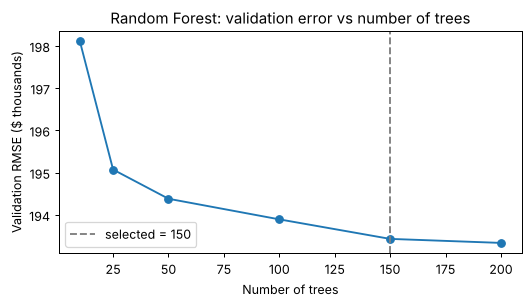

In [6]:
# Stage 3: n_estimators. warm_start adds trees to the same forest, so the first k trees
# are exactly the forest we would get by fitting k trees from scratch with random_state=42.
forest = RandomForestRegressor(
    n_estimators=10, max_features=best_max_features, max_depth=best_max_depth,
    min_samples_leaf=1, n_jobs=-1, random_state=42, warm_start=True,
)

tree_counts = [10, 25, 50, 100, 150, 200]
for n_trees in tree_counts:
    start = time.time()
    forest.set_params(n_estimators=n_trees)
    forest.fit(Xtr, y_train)
    result = evaluate_predictions(f"RF n_estimators={n_trees}", y_val, forest.predict(Xva))
    result.update(stage="3: n_estimators", n_estimators=n_trees,
                  max_features=str(best_max_features), max_depth=str(best_max_depth),
                  fit_seconds=round(time.time() - start, 1))
    tuning_rows.append(result)
    print(f"n_estimators={n_trees:>3} | RMSE=${result['RMSE']:,.0f} | "
          f"MAE=${result['MAE']:,.0f} | R²={result['R2']:.4f}")

stage3 = pd.DataFrame(tuning_rows).query("stage == '3: n_estimators'").reset_index(drop=True)

# Choose the smallest forest within 0.25% of the best validation RMSE:
# beyond that point extra trees cost time and memory for a negligible gain.
best_rmse = stage3["RMSE"].min()
best_n_estimators = int(stage3.loc[stage3["RMSE"] <= best_rmse * 1.0025, "n_estimators"].min())
print("\nSelected n_estimators:", best_n_estimators)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(stage3["n_estimators"], stage3["RMSE"] / 1000, marker="o")
ax.axvline(best_n_estimators, color="grey", linestyle="--", label=f"selected = {best_n_estimators}")
ax.set_xlabel("Number of trees")
ax.set_ylabel("Validation RMSE ($ thousands)")
ax.set_title("Random Forest: validation error vs number of trees")
ax.legend()
plt.tight_layout()
plt.show()

In [7]:
# Final model: the first best_n_estimators trees of the forest above (fitted on 2017–2023 only)
final_rf = forest
final_rf.estimators_ = final_rf.estimators_[:best_n_estimators]
final_rf.set_params(n_estimators=best_n_estimators, warm_start=False)

best_params = {
    "n_estimators": best_n_estimators,
    "max_depth": best_max_depth,
    "max_features": best_max_features,
}
print("Selected configuration:", best_params)

tuning_table = pd.DataFrame(tuning_rows)[
    ["stage", "n_estimators", "max_features", "max_depth", "MAE", "RMSE", "R2", "fit_seconds"]
]
tuning_table.round(4)

Selected configuration: {'n_estimators': 150, 'max_depth': 25, 'max_features': 1.0}


,stage,n_estimators,max_features,max_depth,MAE,RMSE,R2,fit_seconds
0,1: max_features,50,sqrt,20,111978.1164,203726.7599,0.7797,61.9
1,1: max_features,50,0.2,20,110163.0662,199849.6986,0.7880,101.6
2,1: max_features,50,0.33,20,108868.9345,197462.7371,0.7931,154.6
3,1: max_features,50,0.5,20,107935.3937,196429.6216,0.7952,222.0
4,1: max_features,50,1.0,20,107186.8217,195604.7559,0.7969,437.7
5,2: max_depth,50,1.0,10,120979.9385,215246.2695,0.7541,291.7
6,2: max_depth,50,1.0,15,111171.8899,199932.5265,0.7879,389.1
7,2: max_depth,50,1.0,20,107186.8217,195604.7559,0.7969,429.6
8,2: max_depth,50,1.0,25,106257.8421,194381.9565,0.7995,464.9
9,2: max_depth,50,1.0,None,106164.7286,195168.5959,0.7978,485.9


## 5. Does the Forest Reduce Variance?

We check the variance argument from Section 1 in three ways, all on the 2024 validation set:

1. **Individual trees vs the forest:** the error of each tree on its own compared with the error of their average.
2. **Disagreement between trees:** how much the trees' predictions differ for the same property.
3. **Overfitting gap:** training vs validation error for the single tree and the forest.

,quantity,value
0,Mean RMSE of an individual tree,237687.1716
1,Best individual tree RMSE,224646.4543
2,Forest RMSE (average of all trees),193431.9080
3,Average pairwise correlation of tree errors,0.6222
4,Average std. of tree predictions per property,91867.0429


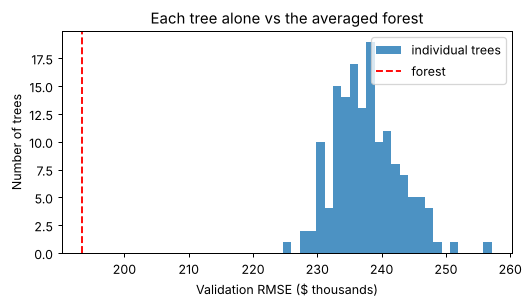

In [8]:
# Predictions of every tree on the validation set: shape (n_trees, n_val)
tree_val_preds = np.vstack([tree.predict(Xva) for tree in final_rf.estimators_])
forest_val_pred = tree_val_preds.mean(axis=0)

individual_rmse = np.sqrt(((tree_val_preds - y_val.to_numpy()) ** 2).mean(axis=1))
forest_rmse = np.sqrt(mean_squared_error(y_val, forest_val_pred))

# Average correlation between the errors of different trees (estimate of rho)
tree_errors = tree_val_preds - y_val.to_numpy()
corr = np.corrcoef(tree_errors)
avg_error_corr = corr[np.triu_indices_from(corr, k=1)].mean()

# Spread of the individual tree predictions for the same property
avg_tree_spread = tree_val_preds.std(axis=0).mean()

variance_summary = pd.DataFrame({
    "quantity": [
        "Mean RMSE of an individual tree",
        "Best individual tree RMSE",
        "Forest RMSE (average of all trees)",
        "Average pairwise correlation of tree errors",
        "Average std. of tree predictions per property",
    ],
    "value": [individual_rmse.mean(), individual_rmse.min(), forest_rmse,
              avg_error_corr, avg_tree_spread],
})
display(variance_summary.round(4))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(individual_rmse / 1000, bins=25, alpha=0.8, label="individual trees")
ax.axvline(forest_rmse / 1000, color="red", linestyle="--", label="forest")
ax.set_xlabel("Validation RMSE ($ thousands)")
ax.set_ylabel("Number of trees")
ax.set_title("Each tree alone vs the averaged forest")
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
# Overfitting gap: single tree vs forest (training error on the same 30,000-row sample)
gap = pd.DataFrame([
    {**evaluate_predictions("Single tree", y_train.iloc[train_sample], single_tree.predict(Xtr[train_sample])),
     "split": "Training (sample)"},
    {**evaluate_predictions("Single tree", y_val, single_tree.predict(Xva)), "split": "Validation 2024"},
    {**evaluate_predictions("Random Forest", y_train.iloc[train_sample], final_rf.predict(Xtr[train_sample])),
     "split": "Training (sample)"},
    {**evaluate_predictions("Random Forest", y_val, forest_val_pred), "split": "Validation 2024"},
])[["model", "split", "MAE", "RMSE", "R2"]]
gap.round(4)

,model,split,MAE,RMSE,R2
0,Single tree,Training (sample),3338.8284,17867.5955,0.9975
1,Single tree,Validation 2024,125782.0201,233691.5481,0.7102
2,Random Forest,Training (sample),32702.2170,57789.6097,0.9743
3,Random Forest,Validation 2024,105920.1784,193431.9080,0.8014


## 6. Final Test Evaluation

The configuration is now fixed. We evaluate it once on the 2025 test set and compare it with the
training-mean baseline. The encoder and the forest remain fitted on 2017–2023 data only.

In [10]:
val_predictions = forest_val_pred
test_predictions = final_rf.predict(Xte)

final_results = pd.DataFrame([
    {**baseline_val, "split": "Validation 2024"},
    {**evaluate_predictions("Random Forest", y_val, val_predictions), "split": "Validation 2024"},
    {**evaluate_predictions("Mean baseline", y_test, np.full(len(y_test), train_mean)), "split": "Test 2025"},
    {**evaluate_predictions("Random Forest", y_test, test_predictions), "split": "Test 2025"},
])[["split", "model", "MAE", "RMSE", "R2"]]

print("Final configuration:", best_params)
display(final_results.round(4))
print("Negative test predictions:", int((test_predictions < 0).sum()))

Final configuration: {'n_estimators': 150, 'max_depth': 25, 'max_features': 1.0}


,split,model,MAE,RMSE,R2
0,Validation 2024,Mean baseline,227823.9716,444016.5549,-0.0463
1,Validation 2024,Random Forest,105920.1784,193431.9080,0.8014
2,Test 2025,Mean baseline,249127.9742,551842.5913,-0.0518
3,Test 2025,Random Forest,124355.8886,272307.2620,0.7439


Negative test predictions: 0


## 7. Error Analysis

We use the same price bands and sign convention as the Ridge notebook:
signed error = predicted − actual, so a negative mean error means underprediction.

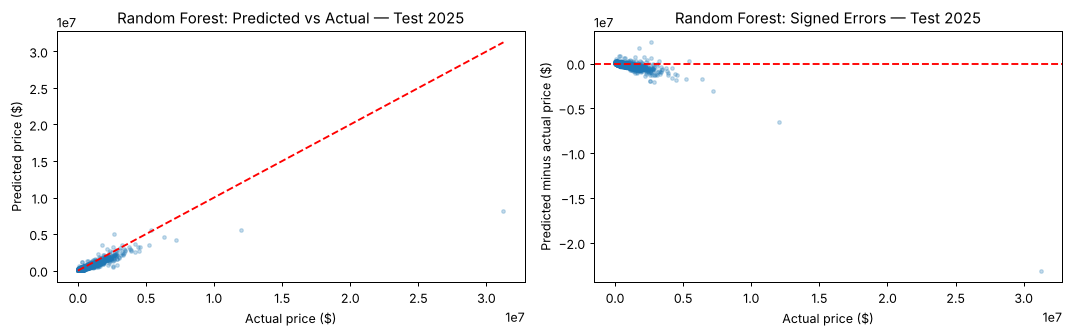

,records,MAE,mean_error
price_band,,,
Up to $250k,8694,55003.62,3237.27
$250k–$500k,14348,83885.76,-72300.42
$500k–$1M,6070,170208.72,-158996.64
Above $1M,2423,497978.41,-468980.40


In [11]:
test_errors = pd.DataFrame({
    "actual_price": y_test.to_numpy(),
    "predicted_price": test_predictions,
})
test_errors["error"] = test_errors["predicted_price"] - test_errors["actual_price"]
test_errors["absolute_error"] = test_errors["error"].abs()
test_errors["price_band"] = pd.cut(
    test_errors["actual_price"],
    bins=[0, 250_000, 500_000, 1_000_000, np.inf],
    labels=["Up to $250k", "$250k–$500k", "$500k–$1M", "Above $1M"],
    include_lowest=True,
)

plot_sample = test_errors.sample(n=min(5000, len(test_errors)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(plot_sample["actual_price"], plot_sample["predicted_price"], s=8, alpha=0.25)
upper = max(plot_sample["actual_price"].max(), plot_sample["predicted_price"].max())
axes[0].plot([0, upper], [0, upper], "r--")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Random Forest: Predicted vs Actual — Test 2025")
axes[1].scatter(plot_sample["actual_price"], plot_sample["error"], s=8, alpha=0.25)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Actual price ($)")
axes[1].set_ylabel("Predicted minus actual price ($)")
axes[1].set_title("Random Forest: Signed Errors — Test 2025")
plt.tight_layout()
plt.show()

band_results = test_errors.groupby("price_band", observed=True).agg(
    records=("actual_price", "size"),
    MAE=("absolute_error", "mean"),
    mean_error=("error", "mean"),
)
band_results.round(2)

## 8. Which Features Does the Forest Use?

Impurity-based importance shows how much each feature reduced squared error across all splits. It is
quick but can favour features with many distinct values, so we also run a **grouped permutation test**
on the validation set: we shuffle all property-characteristic inputs (or all location and contextual
inputs) at once and measure how much validation RMSE increases. This feeds directly into the group's
Phase 4 question of whether geographic indicators matter.

In [12]:
importances = pd.Series(final_rf.feature_importances_, index=feature_names).sort_values(ascending=False)
display(importances.head(15).round(4).to_frame("impurity importance"))

groups = {
    "Property characteristics (char_*)": [i for i, f in enumerate(feature_names) if f.startswith("char_")],
    "Location & context (loc_*, prox_*, shp_*)": [i for i, f in enumerate(feature_names) if not f.startswith("char_")],
    "Coordinates only (latitude, longitude)": [feature_names.index("loc_latitude"), feature_names.index("loc_longitude")],
}

perm_rng = np.random.default_rng(0)
perm_rows = []
for group, cols in groups.items():
    increases = []
    for _ in range(3):
        Xperm = Xva.copy()
        rows = perm_rng.permutation(len(Xperm))
        Xperm[:, cols] = Xperm[rows][:, cols]          # shuffle the group's columns together
        rmse = np.sqrt(mean_squared_error(y_val, final_rf.predict(Xperm)))
        increases.append(rmse - forest_rmse)
    perm_rows.append({"feature group": group, "features": len(cols),
                      "RMSE increase when shuffled ($)": np.mean(increases)})
group_importance = pd.DataFrame(perm_rows)
group_importance.round(0)

,impurity importance
char_bldg_sf,0.4397
prox_lake_michigan_dist_ft,0.1969
loc_latitude,0.0825
char_yrblt,0.0267
prox_airport_dnl_total,0.0215
loc_longitude,0.0169
loc_access_cmap_walk_total_score,0.0155
prox_nearest_university_dist_ft,0.0148
char_land_sf,0.0127
loc_access_cmap_walk_nta_score,0.0071


,feature group,features,RMSE increase when shuffled ($)
0,Property characteristics (char_*),25,198772.0
1,"Location & context (loc_*, prox_*, shp_*)",56,212573.0
2,"Coordinates only (latitude, longitude)",2,103701.0


## 9. Export Results for the Group

In [13]:
from pathlib import Path
import json

results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

tuning_table.to_csv(results_dir / "rf_validation_tuning.csv", index=False)
final_results.to_csv(results_dir / "rf_metrics.csv", index=False)
band_results.to_csv(results_dir / "rf_errors_by_price_band.csv")
importances.to_frame("impurity_importance").to_csv(results_dir / "rf_feature_importance.csv")
group_importance.to_csv(results_dir / "rf_group_permutation_importance.csv", index=False)

predictions_export = test_errors.copy()
predictions_export.insert(0, "source_row_index", X_test.index.to_numpy())
predictions_export.to_csv(results_dir / "rf_test_predictions.csv", index=False)

(results_dir / "rf_config.json").write_text(json.dumps({
    "n_estimators": best_n_estimators,
    "max_depth": best_max_depth,
    "max_features": best_max_features,
    "min_samples_leaf": 1,
    "bootstrap": True,
    "random_state": 42,
    "selection_metric": "validation RMSE",
    "training_period": "2017–2023",
    "validation_period": "2024",
    "test_period": "2025",
    "input_features": 81,
    "encoder": "make_tree_encoder (ordinal categories, unscaled numerics)",
    "target_transformation": "none",
    "prediction_clipping": False,
}, indent=2), encoding="utf-8")

print("Results saved to:", results_dir.resolve())

Results saved to: /home/claude/rfrun/results


## 10. Results and Discussion

### Parameter Selection

| Stage | Candidates (validation RMSE, 50 trees unless stated) | Selected |
|---|---|---|
| `max_features` (depth 20) | √p: \$203,727 · 0.2: \$199,850 · 0.33: \$197,463 · 0.5: \$196,430 · 1.0: \$195,605 | **1.0** |
| `max_depth` (all features) | 10: \$215,246 · 15: \$199,933 · 20: \$195,605 · 25: \$194,382 · None: \$195,169 | **25** |
| `n_estimators` (depth 25) | 10: \$198,114 · 25: \$195,073 · 50: \$194,382 · 100: \$193,894 · 150: \$193,432 · 200: \$193,337 | **150** |

- **`max_features`:** validation error fell steadily as more features were allowed at each split, and
  using all features (plain bagging) was best. The gain from 0.5 to 1.0 was small (about \$800, 0.4%)
  but the fit time doubled. A few features (building area, distance to Lake Michigan, latitude) carry
  most of the signal, so restricting the split candidates often hides them from a split.
- **`max_depth`:** depth 10 underfits clearly (R² 0.754). Error improves up to depth 25; fully grown
  trees were slightly worse on validation (\$195,169 vs \$194,382), so we cap depth at 25. This also
  keeps the trees smaller in memory.
- **`n_estimators`:** most of the improvement arrives in the first 25–50 trees; beyond 100 trees the
  gains are a few hundred dollars. We keep **150 trees**, the smallest forest within 0.25% of the best
  validation RMSE (200 trees). The 50-tree point reproduces the stage 2 result exactly, which confirms
  the warm-start forest matches a forest fitted from scratch.

### Variance Reduction

| | Training (30k sample) R² | Validation 2024 R² | Validation RMSE |
|---|---:|---:|---:|
| Single fully grown tree | 0.9975 | 0.7102 | \$233,692 |
| Random Forest (150 trees) | 0.9743 | 0.8014 | \$193,432 |

- A single unpruned tree nearly memorises the training data (R² 0.998, depth 66, 257,079 leaves)
  but reaches only R² 0.710 on 2024 sales: the classic high-variance pattern.
- The individual trees inside the forest have a mean validation RMSE of **\$237,687** (the best single
  tree: \$224,646). Averaging them gives **\$193,432**, an 18.6% reduction, and better than *every*
  individual tree. This is the variance reduction that bagging is designed to deliver.
- For the same property, the 150 trees' predictions differ by about **\$91,867** (average standard
  deviation). Averaging removes much of this tree-to-tree noise.
- The reduction is limited by correlation: the trees' errors have an average pairwise correlation of
  **0.62**. With all features available at every split, the trees often choose the same top splits,
  so part of the variance ($\rho\sigma^2$) cannot be averaged away. Smaller `max_features` lowers this
  correlation but, on our data, made each tree weaker by more than it gained.
- The forest still fits training sales far better than validation sales (R² 0.974 vs 0.801). The
  remaining gap reflects deep trees and, as discussed below, the shift in prices between periods.

### Final Performance

| Model | Split | MAE (USD) | RMSE (USD) | R² |
|---|---|---:|---:|---:|
| Mean baseline | Validation 2024 | 227,823.97 | 444,016.55 | -0.0463 |
| Random Forest | Validation 2024 | 105,920.18 | 193,431.91 | 0.8014 |
| Mean baseline | Test 2025 | 249,127.97 | 551,842.59 | -0.0518 |
| Random Forest | Test 2025 | 124,355.89 | 272,307.26 | 0.7439 |

On 2025 sales, Random Forest halves the baseline MAE (−50.1%) and explains 74.4% of price variance.
For context, on the same test set Ridge reached R² 0.582 (MAE \$147,267) and Gradient Boosting
R² 0.766 (MAE \$125,945). Random Forest has a slightly lower MAE than Gradient Boosting but a higher
RMSE, i.e. it is marginally better on typical homes and worse on the largest errors.
No predictions are negative, since every tree predicts an average of observed training prices.

### Errors Across Price Bands (Test 2025)

| Actual price band | Records | MAE (USD) | Mean signed error (USD) |
|---|---:|---:|---:|
| Up to \$250k | 8,694 | 55,003.62 | +3,237.27 |
| \$250k–\$500k | 14,348 | 83,885.76 | −72,300.42 |
| \$500k–\$1M | 6,070 | 170,208.72 | −158,996.64 |
| Above \$1M | 2,423 | 497,978.41 | −468,980.40 |

Signed error is predicted minus actual. Errors are close to unbiased for cheaper homes but the forest
increasingly **underpredicts** more expensive homes, reaching an average of −\$469k above \$1M.
Overall, 79.4% of 2025 test sales are underpredicted (median signed error −\$73,796).

Two effects contribute. First, prices rose over time: the mean sale price is \$350,714 in training,
\$444,157 in 2024 and \$473,135 in 2025. A tree can only predict averages of training prices and has
no sale-date input, so it cannot extrapolate this upward drift. Second, sales above \$1M are rare in
training, and leaf averages pull them towards the denser middle of the distribution. This analysis
describes the fixed model; the test results were not used to change it.

### Which Inputs Matter

- **Impurity importance** is dominated by building area (`char_bldg_sf`, 0.44), distance to Lake
  Michigan (0.20) and latitude (0.08), followed by year built, airport noise, longitude and walkability.
- **Grouped permutation on 2024 validation data:** shuffling all 56 location and contextual inputs
  increases RMSE by about **\$212,573**; shuffling all 25 property characteristics increases it by
  **\$198,772**. Shuffling only latitude and longitude increases it by **\$103,701**. Location
  information is therefore at least as important as the physical characteristics of the house.
  This answers part of the group's Phase 4 question on geographic indicators.

### Limitations

- The forest cannot extrapolate beyond the range of training prices, which matters under a
  chronological split with rising prices.
- `max_features=1.0` is expensive: a 150-tree forest takes several minutes to train on 276,685 sales.
- Tuning was sequential (one parameter at a time) rather than a full grid, so interactions between
  parameters were only partly explored. Validation differences between the best settings are small.
- As for the other models, the historical availability of every contextual input has not been
  verified, and the test set includes properties also sold during the training period.

## 11. Conclusion

Random Forest substantially improves on both the mean baseline and Ridge, reaching a 2025 test
R² of 0.744 and MAE of \$124,356, close to Gradient Boosting. Averaging 150 deep trees reduced
validation RMSE by 18.6% relative to an individual tree and removed most of the single tree's
overfitting, confirming the variance-reduction effect of bagging. The main remaining weakness is
systematic underprediction of expensive homes and of 2025 prices in general. With more time we would
try a log-price target, add a sale-date or price-index feature so the model can follow market
trends, and compare against out-of-bag error estimates.